In [1]:
!pip install -q kagglehub scikit-learn pandas matplotlib scipy

# downloading data from kaggle directly instead of uploading each time

In [2]:
import os

# 1. Provide your Kaggle credentials directly as text strings
os.environ['KAGGLE_USERNAME'] = "marammohamedhanafy"
os.environ['KAGGLE_KEY'] = "KGAT_9a09f75b78beb7c557afc93fbecc2882"  #this kaggle api key = credintials just for me = maram , you can change and set your own user , api key

# 2. Download the raw dataset directly via CLI
!kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset

# 3. Unzip and extract into a dedicated directory
!unzip -q brain-tumor-mri-dataset.zip -d data
!rm brain-tumor-mri-dataset.zip

print("Download complete! Files are inside the 'data' folder.")


Dataset URL: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 157M/157M [00:01<00:00, 93.9MB/s]

Download complete! Files are inside the 'data' folder.


In [3]:
import os, json, time, hashlib, shutil, random, copy
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report

# ---- must be identical to Member 1 ----
TEAM_ID = "34"
SEED = 42
CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
IMAGE_SIZE = 224
BATCH_SIZE = 32
DATA_DIR = "/content/data"
TF_DIR = "/content/outputs_tensorflow_aug"              # Member 1's output folder (unzipped)
# ---- PyTorch side ----
OUT_DIR, MODEL_DIR, CACHE_DIR = "outputs_pytorch", "model", "cache"
QUICK = False            # True = tiny subset + 2 epochs, only to test the notebook end-to-end
PRETRAINED = True
CHECK_COUNTS = True
SANITY_STEPS = 40

for d in ("data", OUT_DIR, MODEL_DIR, CACHE_DIR):
    os.makedirs(d, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print(torch.__version__, torchvision.__version__, DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "")

2.11.0+cu130 0.26.0+cu130 cuda Tesla T4


## 1. Same data, same split
Best way to be *exactly* fair: reuse Member 1's `split_manifest.csv` (upload `outputs_tensorflow_aug.zip` next to this notebook). If it is missing, the cell rebuilds the split with the identical code + seed and asserts the same counts (4909 / 1052 / 1052).

In [4]:
if os.path.exists("outputs_tensorflow_aug.zip") and not os.path.isdir(TF_DIR):
    shutil.unpack_archive("outputs_tensorflow_aug.zip", TF_DIR)
print("Member-1 outputs:", sorted(os.listdir(TF_DIR)) if os.path.isdir(TF_DIR) else "NOT FOUND")

if not os.path.exists(DATA_DIR):
    import kagglehub
    src = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
    shutil.copytree(src, DATA_DIR, dirs_exist_ok=True)
print(os.listdir(DATA_DIR))

def file_md5(p):
    with open(p, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()

def resolve(p):  # map a path from Member 1's manifest onto this machine: .../Training/<label>/<file>
    return f"{DATA_DIR}/" + "/".join(p.replace("\\", "/").split("/")[-3:])

MANIFEST = f"{TF_DIR}/split_manifest.csv"
if os.path.exists(MANIFEST):
    manifest = pd.read_csv(MANIFEST)
    manifest["path"] = manifest["path"].map(resolve)
    assert all(os.path.exists(p) for p in manifest["path"]), "some manifest files are missing"
    chk = manifest.sample(min(100, len(manifest)), random_state=0)
    assert all(file_md5(p) == m for p, m in zip(chk["path"], chk["md5"])), "files differ from Member 1's data!"
    SPLIT_SOURCE = "Member 1 manifest (identical files verified by md5)"
else:
    rows = []
    for root, _, files in os.walk(DATA_DIR):
        label = os.path.basename(root)
        if label in CLASS_NAMES:
            for f in files:
                if f.lower().endswith((".jpg", ".jpeg", ".png")):
                    rows.append({"path": os.path.join(root, f).replace(os.sep, "/"), "label": label})
    df = pd.DataFrame(rows).sort_values("path").reset_index(drop=True)
    df["md5"] = df["path"].apply(file_md5)
    n_dup = int(df.duplicated("md5").sum())
    df = df.drop_duplicates("md5").reset_index(drop=True)
    df["label_idx"] = df["label"].map({c: i for i, c in enumerate(CLASS_NAMES)})
    tr, tmp = train_test_split(df, test_size=0.30, stratify=df["label_idx"], random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.50, stratify=tmp["label_idx"], random_state=SEED)
    manifest = pd.concat([tr.assign(split="train"), va.assign(split="val"), te.assign(split="test")], ignore_index=True)
    SPLIT_SOURCE = f"rebuilt with seed {SEED} ({n_dup} duplicates removed)"
    if CHECK_COUNTS:
        assert manifest["split"].value_counts().to_dict() == {"train": 4909, "val": 1052, "test": 1052}, "split differs from Member 1!"

parts = {s: manifest[manifest["split"] == s].sort_values("path").reset_index(drop=True) for s in ("train", "val", "test")}
train_df, val_df, test_df = parts["train"], parts["val"], parts["test"]
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not set(a["md5"]) & set(b["md5"]), "leakage between splits"

if QUICK:  # tiny subsets just to test the pipeline
    train_df = train_df.sample(min(256, len(train_df)), random_state=SEED).sort_values("path").reset_index(drop=True)
    val_df = val_df.sample(min(128, len(val_df)), random_state=SEED).sort_values("path").reset_index(drop=True)
    test_df = test_df.sample(min(128, len(test_df)), random_state=SEED).sort_values("path").reset_index(drop=True)

all_df = pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")], ignore_index=True)
counts = pd.crosstab(all_df["label"], all_df["split"])[["train", "val", "test"]].loc[CLASS_NAMES]
counts.loc["total"] = counts.sum()
counts.to_csv(f"{OUT_DIR}/split_counts.csv")
print("split source:", SPLIT_SOURCE); print(counts)

Member-1 outputs: ['classification_report_tensorflow.txt', 'confusion_matrix_tensorflow.csv', 'confusion_matrix_tensorflow.png', 'gradcam_tensorflow.png', 'loss_curves_tensorflow.png', 'preprocessing_spec.json', 'sample_augmentations.png', 'split_counts.csv', 'split_manifest.csv', 'tensorflow_results.json', 'training_history.csv']
['Training', 'Testing']
split source: Member 1 manifest (identical files verified by md5)
split       train   val  test
label                        
glioma       1250   268   268
meningioma   1249   267   268
notumor      1177   252   252
pituitary    1233   265   264
total        4909  1052  1052


## 2. Same preprocessing + augmentation
| | TensorFlow (Member 1) | PyTorch (here) |
|---|---|---|
| resize | `tf.image.resize` bilinear, no antialias | `F.interpolate(bilinear, antialias=False)` |
| normalization | `resnet50.preprocess_input` (BGR, mean-subtract) | ImageNet mean/std (what torchvision weights expect) |
| augmentation | rotation ±10°, shift ±5 %, zoom ±5 %, black fill, **train only** | `RandomAffine(10°, 5 %, scale 0.95–1.05, fill=0)`, **train only** |

The normalization differs *on purpose*: each framework must feed its own pretrained weights the format they were trained with. Everything else is identical. Images are cached as `uint8` tensors (rounding error ≤ 0.5/255) so training is not bottlenecked by JPEG decoding.

torch.Size([4909, 3, 224, 224]) torch.uint8 26s


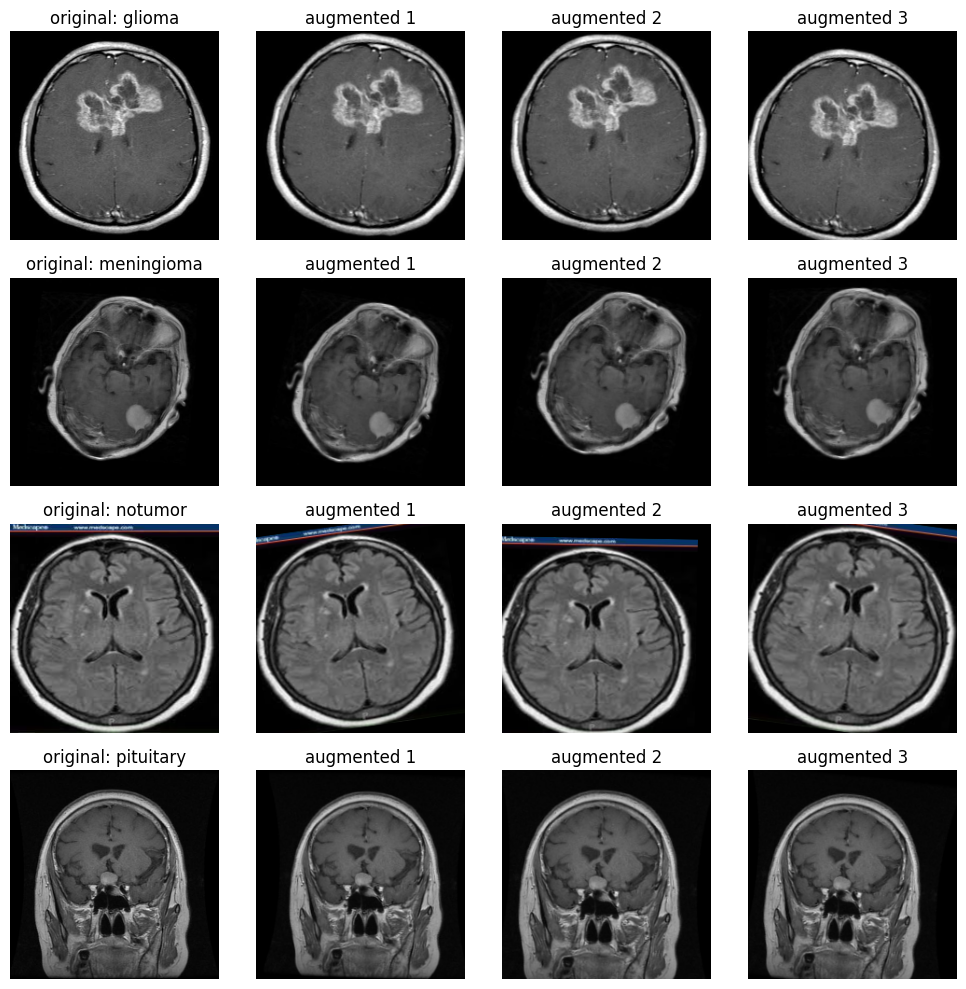

In [5]:
def load_resized(path):
    img = Image.open(path).convert("RGB")
    t = torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1).float()[None]
    t = F.interpolate(t, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False, antialias=False)
    return t.round().clamp(0, 255).to(torch.uint8)[0]

def load_split(frame, name):
    key = hashlib.md5("".join(frame["md5"]).encode()).hexdigest()[:8]
    cache = f"{CACHE_DIR}/{name}_{key}.pt"
    if os.path.exists(cache):
        return torch.load(cache)
    X = torch.stack([load_resized(p) for p in frame["path"]])
    torch.save(X, cache)
    return X

t0 = time.time()
X_train, X_val, X_test = load_split(train_df, "train"), load_split(val_df, "val"), load_split(test_df, "test")
y_train, y_val, y_test = (torch.tensor(d["label_idx"].values, dtype=torch.long) for d in (train_df, val_df, test_df))
print(X_train.shape, X_train.dtype, f"{time.time() - t0:.0f}s")

AUG = {"rotation_deg": 10, "translation_frac": 0.05, "zoom_frac": 0.05, "fill": 0, "flips": False, "intensity_changes": False,
       "applied_to": "training set only"}
train_aug = v2.RandomAffine(degrees=AUG["rotation_deg"], translate=(AUG["translation_frac"],) * 2,
                            scale=(1 - AUG["zoom_frac"], 1 + AUG["zoom_frac"]),
                            interpolation=v2.InterpolationMode.BILINEAR, fill=0)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
def prep(x_uint8):  # uint8 NCHW on device -> normalized float
    x = x_uint8.to(DEVICE, non_blocking=True).float().div_(255)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)

class MRIDataset(Dataset):
    def __init__(self, X, y, aug=None):
        self.X, self.y, self.aug = X, y, aug
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x = self.X[i]
        return (self.aug(x) if self.aug else x), self.y[i]

def make_train_loader(seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(MRIDataset(X_train, y_train, train_aug), batch_size=BATCH_SIZE, shuffle=True, generator=g,
                      num_workers=0 if QUICK else 2, pin_memory=USE_AMP, persistent_workers=not QUICK)

# visual check: augmentation must be mild and must not crop the tumour
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for r, name in enumerate(CLASS_NAMES):
    i = int((y_train == r).nonzero()[0])
    axes[r, 0].imshow(X_train[i].permute(1, 2, 0)); axes[r, 0].set_title(f"original: {name}")
    for c in range(1, 4):
        axes[r, c].imshow(train_aug(X_train[i]).permute(1, 2, 0)); axes[r, c].set_title(f"augmented {c}")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/sample_augmentations.png", dpi=120); plt.show()

## 3. Model: ResNet50 + configurable trainable head
* Backbone: torchvision ResNet50 with `IMAGENET1K_V1` weights (the classic ImageNet model — closest to Keras' ResNet50 weights).
* **BatchNorm stays frozen (eval mode) everywhere**, exactly like Member 1 (`BatchNormalization` layers kept non-trainable). Forgetting this in PyTorch is the #1 silent difference: `model.train()` would otherwise update BN statistics with batch-32 medical images.
* Head options: `linear` = GAP → Dropout → Linear (matches TF) · `mlp` = GAP → Dropout → Linear(512) → ReLU → Dropout → Linear.
* Unfreezing "last 30 Keras layers" ≈ the whole `layer4` (= `conv5` stage) in torchvision, so the matched baseline unfreezes `layer4` convs.

In [7]:
class Net(nn.Module):
    def __init__(self, arch="resnet50", head="linear", hidden=512, dropout=0.3, pretrained=PRETRAINED):
        super().__init__()
        self.backbone = torchvision.models.get_model(arch, weights="IMAGENET1K_V1" if pretrained else None)
        f = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        if head == "linear":
            self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(f, len(CLASS_NAMES)))
        elif head == "mlp":
            self.head = nn.Sequential(nn.Dropout(dropout)
                                     ,nn.Linear(f, 256),
                                      nn.ReLU(inplace=True),
                                      nn.Dropout(dropout),
                                      nn.Linear(256, 128),
                                      nn.ReLU(inplace=True),
                                      nn.Dropout(dropout),
                                      nn.Linear(128, len(CLASS_NAMES)))
        else:
            raise ValueError(head)
        self.backbone_frozen = True

    def train(self, mode=True):
        super().train(mode)
        for m in self.backbone.modules():           # keep BatchNorm in inference mode (as in the TF notebook)
            if isinstance(m, nn.BatchNorm2d):
                m.eval()
        return self

    def forward(self, x):
        if self.backbone_frozen:
            with torch.no_grad():
                f = self.backbone(x)
        else:
            f = self.backbone(x)
        return self.head(f)                          # logits (softmax is applied in the loss / at inference)

def set_trainable(model, unfreeze):
    """unfreeze=[] -> only the head trains; ['layer4'] -> head + all convs of layer4; BatchNorm never trains."""
    for p in model.backbone.parameters():
        p.requires_grad = False
    for stage in unfreeze:
        for m in getattr(model.backbone, stage).modules():
            if isinstance(m, nn.Conv2d):
                for p in m.parameters():
                    p.requires_grad = True
    for p in model.head.parameters():
        p.requires_grad = True
    model.backbone_frozen = len(unfreeze) == 0

def n_params(model, trainable=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable))

m = Net().to(DEVICE)
set_trainable(m, [])
print("phase 1 trainable:", n_params(m, True), "/", n_params(m))
set_trainable(m, ["layer4"])
print("phase 2 trainable (layer4):", n_params(m, True))
del m

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]


phase 1 trainable: 8196 / 23516228
phase 2 trainable (layer4): 14950404


## 4. Debugging toolkit — run BEFORE long trainings
Five 1-minute checks that catch ~90 % of "my model doesn't learn" problems:
1. **Input check** — shapes, dtype, value range after normalization, labels balanced.
2. **Initial loss ≈ ln(4) ≈ 1.39** — if it is 10+, labels/logits/loss are mismatched.
3. **Overfit one batch** — loss must go to ≈ 0. If not, there is a *bug* (not a tuning problem).
4. **Gradient flow** — every trainable group must get non-zero, finite gradients.
5. **Which parameters train / BN mode** — prevents the silent BatchNorm trap.

In [8]:
@torch.no_grad()
def get_logits(model, X, amp=False, bs=128):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp and USE_AMP):
            out.append(model(prep(X[i:i + bs])).float().cpu())
    return torch.cat(out)

def compute_metrics(logits, y, loss_name="loss"):
    prob = logits.softmax(1).numpy(); pred = prob.argmax(1); yt = y.numpy()
    p, r, f, _ = precision_recall_fscore_support(yt, pred, average="macro", zero_division=0)
    return {"accuracy": float((pred == yt).mean()), "precision_macro": float(p), "recall_macro": float(r),
            "f1_macro": float(f), loss_name: float(F.cross_entropy(logits, y))}

def sanity_checks(arch="resnet50", steps=SANITY_STEPS):
    xb, yb = next(iter(make_train_loader()))
    print("1) batch:", tuple(xb.shape), xb.dtype, "| labels in batch:", dict(Counter(yb.tolist())))
    xn = prep(xb)
    print(f"   normalized: min {xn.min():.2f} max {xn.max():.2f} mean {xn.mean():.2f} std {xn.std():.2f}  (MRI is mostly black, so mean<0 is normal; NaN or |x|>5 is a bug)")
    model = Net(arch).to(DEVICE).to(memory_format=torch.channels_last)
    set_trainable(model, ["layer4"]); model.train()
    x, y = xn.to(DEVICE), yb.to(DEVICE)
    with torch.no_grad():
        l0 = F.cross_entropy(model(x), y).item()
    print(f"2) initial loss {l0:.3f}  (expected ≈ {np.log(4):.2f}; much larger -> check labels / loss / logits)")
    model.head.eval()                                   # dropout off: we want to see pure memorization
    opt = torch.optim.Adam([{"params": model.head.parameters(), "lr": 1e-3},
                            {"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": 1e-4}])
    for s in range(steps):
        opt.zero_grad(); loss = F.cross_entropy(model(x), y); loss.backward(); opt.step()
    print(f"3) overfit-one-batch: loss {l0:.3f} -> {loss.item():.4f} after {steps} steps  (should be ≈ 0; if not, there is a BUG)")
    for name, params in [("head", model.head.parameters()), ("layer4", model.backbone.layer4.parameters()),
                         ("layer3 (frozen)", model.backbone.layer3.parameters())]:
        g = [p.grad.norm().item() for p in params if p.grad is not None]
        print(f"4) grad-norm {name:16s}: {np.sqrt(np.sum(np.square(g))) if g else 0.0:.4f}" + ("" if g else "  (no grad = frozen, expected)"))
    bn_train = sum(m.training for m in model.modules() if isinstance(m, nn.BatchNorm2d))
    print(f"5) BatchNorm layers in train mode: {bn_train} (must be 0) | trainable params {n_params(model, True):,} / {n_params(model):,}")

sanity_checks()

1) batch: (32, 3, 224, 224) torch.uint8 | labels in batch: {1: 7, 3: 10, 0: 9, 2: 6}
   normalized: min -2.12 max 2.64 mean -1.18 std 0.87  (MRI is mostly black, so mean<0 is normal; NaN or |x|>5 is a bug)
2) initial loss 1.379  (expected ≈ 1.39; much larger -> check labels / loss / logits)
3) overfit-one-batch: loss 1.379 -> 0.0000 after 40 steps  (should be ≈ 0; if not, there is a BUG)
4) grad-norm head            : 0.0000
4) grad-norm layer4          : 0.0001
4) grad-norm layer3 (frozen) : 0.0000  (no grad = frozen, expected)
5) BatchNorm layers in train mode: 0 (must be 0) | trainable params 14,950,404 / 23,516,228


## 5. Training engine + experiments
* **Phase 1** — backbone frozen, train the head. **Phase 2** — unfreeze, small LR, early stopping on val loss (best weights restored) — same protocol as Member 1.
* Every run is configured by a dict; each experiment changes **one idea** so you can say *what* helped (an ablation).
* Validation loss is always plain cross-entropy (so it is comparable with TF even when I train with label smoothing).
* Selection uses the **validation** set only. The test set is touched once at the end.

In [10]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot = correct = n = 0
    for x, y in loader:
        x, y = prep(x), y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
            loss = criterion(logits.float(), y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
        tot += loss.item() * len(y); correct += (logits.argmax(1) == y).sum().item(); n += len(y)
    return tot / n, correct / n

def eval_loop(model, X, y):
    lg = get_logits(model, X, amp=True)
    return F.cross_entropy(lg, y).item(), (lg.argmax(1) == y).float().mean().item()

def fit_phase(model, phase, groups, epochs, patience, opt_name, wd, sched, smoothing, hist, ep0):
    Opt = {"adam": torch.optim.Adam, "adamw": torch.optim.AdamW}[opt_name]
    opt = Opt(groups, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if sched == "cosine" else None
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    crit_tr = nn.CrossEntropyLoss(label_smoothing=smoothing)
    loader = make_train_loader(SEED + ep0)
    best, best_state, best_ep, bad = float("inf"), None, 0, 0
    for ep in range(1, epochs + 1):
        t = time.time()
        tl, ta = run_epoch(model, loader, crit_tr, opt, scaler)
        vl, va = eval_loop(model, X_val, y_val)
        if scheduler: scheduler.step()
        hist.append({"epoch": ep0 + ep, "phase": phase, "loss": tl, "accuracy": ta, "val_loss": vl, "val_accuracy": va,
                     "lr": opt.param_groups[0]["lr"], "sec": time.time() - t})
        print(f"[{phase}] epoch {ep0 + ep:2d} | loss {tl:.4f} acc {ta:.4f} | val_loss {vl:.4f} val_acc {va:.4f} | {time.time() - t:.0f}s")
        if vl < best:
            best, best_ep, bad = vl, ep0 + ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print(f"early stop; best epoch {best_ep}"); break
    model.load_state_dict(best_state)
    return best_ep


BASE = dict(arch="resnet50", head="linear", hidden=512, dropout=0.3,
            p1_lr=1e-3, p1_epochs=15, p1_patience=3,
            unfreeze=["layer4"], head_lr2=1e-5, bb_lr2=1e-5, p2_epochs=20, p2_patience=4,
            opt="adam", wd=0.0, sched="none", label_smoothing=0.0)


EXPS = {   # each experiment = BASE + the overrides below
    "E0_matched_tf":    {},                                                       # mirrors Member 1 exactly -> fair framework comparison
    "E1_mlp_head":      dict(head="mlp" , sched="cosine" , wd=1e-4),                                         # ONLY the head changes
    "E2_higher_ft_lr":  dict(head_lr2=1e-4, bb_lr2=1e-4),                         # ONLY fine-tuning LR x10
    "E3_combined":      dict(head="mlp", unfreeze=["layer4"], head_lr2=3e-4, bb_lr2=1e-4,opt="adamw", wd=1e-4, sched="cosine", label_smoothing=0.1, p2_patience=6),

}
RUN = ["E0_matched_tf", "E1_mlp_head", "E2_higher_ft_lr", "E3_combined"]
FORCE = False   # True = ignore saved results and retrain

def run_experiment(name):
    cfg = {**BASE, **EXPS[name]}
    if QUICK: cfg.update(p1_epochs=2, p2_epochs=2)
    d = f"{OUT_DIR}/{name}"; os.makedirs(d, exist_ok=True)
    if os.path.exists(f"{d}/result.json") and not FORCE:
        print(f"{name}: loaded from disk"); return json.load(open(f"{d}/result.json"))
    print(f"\n===== {name}: {EXPS[name]} =====")
    seed_everything()
    model = Net(cfg["arch"], cfg["head"], cfg["hidden"], cfg["dropout"]).to(DEVICE).to(memory_format=torch.channels_last)
    hist = []
    set_trainable(model, [])
    t0 = time.time()
    best1 = fit_phase(model, "frozen", [{"params": model.head.parameters(), "lr": cfg["p1_lr"]}], cfg["p1_epochs"],
                      cfg["p1_patience"], "adam", 0.0, "none", cfg["label_smoothing"], hist, 0)
    t1 = time.time() - t0
    n1 = len(hist)
    frozen_val = compute_metrics(get_logits(model, X_val), y_val, "val_loss")
    set_trainable(model, cfg["unfreeze"])
    groups = [{"params": model.head.parameters(), "lr": cfg["head_lr2"]},
              {"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": cfg["bb_lr2"]}]
    t0 = time.time()
    best2 = fit_phase(model, "fine_tune", groups, cfg["p2_epochs"], cfg["p2_patience"], cfg["opt"], cfg["wd"],
                      cfg["sched"], cfg["label_smoothing"], hist, n1)
    t2 = time.time() - t0
    val = compute_metrics(get_logits(model, X_val), y_val, "val_loss")
    pd.DataFrame(hist).to_csv(f"{d}/training_history.csv", index=False)
    torch.save(model.state_dict(), f"{d}/best.pt")
    res = {"name": name, "config": cfg, "overrides": EXPS[name], "epochs_phase1": n1, "epochs_phase2": len(hist) - n1,
           "best_epoch_phase1": best1, "best_epoch_phase2": best2, "time_phase1_sec": t1, "time_phase2_sec": t2,
           "total_training_time_sec": t1 + t2, "frozen_backbone_val_metrics": frozen_val, "fine_tuned_val_metrics": val,
           "trainable_params_phase2": n_params(model, True), "total_params": n_params(model)}
    json.dump(res, open(f"{d}/result.json", "w"), indent=2)
    return res

results = {}
for name in RUN:
    results[name] = run_experiment(name)


===== E0_matched_tf: {} =====
[frozen] epoch  1 | loss 0.6828 acc 0.7311 | val_loss 0.4502 val_acc 0.8270 | 12s
[frozen] epoch  2 | loss 0.4567 acc 0.8297 | val_loss 0.3943 val_acc 0.8451 | 12s
[frozen] epoch  3 | loss 0.4216 acc 0.8397 | val_loss 0.3952 val_acc 0.8584 | 12s
[frozen] epoch  4 | loss 0.3921 acc 0.8572 | val_loss 0.3653 val_acc 0.8612 | 12s
[frozen] epoch  5 | loss 0.3789 acc 0.8588 | val_loss 0.3221 val_acc 0.8783 | 12s
[frozen] epoch  6 | loss 0.3627 acc 0.8647 | val_loss 0.3315 val_acc 0.8802 | 12s
[frozen] epoch  7 | loss 0.3648 acc 0.8651 | val_loss 0.3145 val_acc 0.8840 | 12s
[frozen] epoch  8 | loss 0.3536 acc 0.8672 | val_loss 0.3897 val_acc 0.8508 | 12s
[frozen] epoch  9 | loss 0.3504 acc 0.8708 | val_loss 0.3101 val_acc 0.8812 | 12s
[frozen] epoch 10 | loss 0.3326 acc 0.8768 | val_loss 0.3022 val_acc 0.8945 | 12s
[frozen] epoch 11 | loss 0.3318 acc 0.8772 | val_loss 0.3248 val_acc 0.8717 | 12s
[frozen] epoch 12 | loss 0.3379 acc 0.8745 | val_loss 0.3083 val_ac

,changes,val_acc,val_f1,val_loss,best_ep,train_min
experiment,,,,,,
E0_matched_tf,{},0.9401,0.9406,0.1825,18,4.4209
E1_mlp_head,"{'head': 'mlp', 'sched': 'cosine', 'wd': 0.0001}",0.9373,0.9372,0.1869,19,4.6236
E2_higher_ft_lr,"{'head_lr2': 0.0001, 'bb_lr2': 0.0001}",0.9620,0.9621,0.1029,20,4.7785
E3_combined,"{'head': 'mlp', 'unfreeze': ['layer4'], 'head_...",0.9686,0.9689,0.1327,19,5.2257


best on VALIDATION: E3_combined


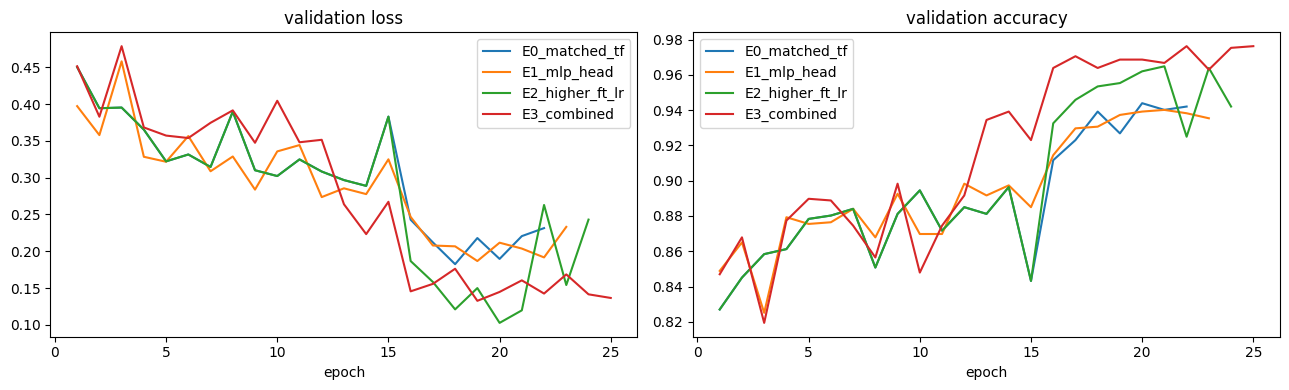

In [11]:
summary = pd.DataFrame([{"experiment": n, "changes": str(r["overrides"]), "val_acc": r["fine_tuned_val_metrics"]["accuracy"],
                         "val_f1": r["fine_tuned_val_metrics"]["f1_macro"], "val_loss": r["fine_tuned_val_metrics"]["val_loss"],
                         "best_ep": r["best_epoch_phase2"], "train_min": r["total_training_time_sec"] / 60}
                        for n, r in results.items()]).set_index("experiment")
summary.to_csv(f"{OUT_DIR}/experiment_summary_val.csv")
display(summary.round(4))
BEST = summary["val_f1"].idxmax()
print("best on VALIDATION:", BEST)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in results:
    h = pd.read_csv(f"{OUT_DIR}/{n}/training_history.csv")
    axes[0].plot(h["epoch"], h["val_loss"], label=n); axes[1].plot(h["epoch"], h["val_accuracy"], label=n)
axes[0].set_title("validation loss"); axes[1].set_title("validation accuracy")
for a in axes: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/experiments_val_curves.png", dpi=130); plt.show()

### How to read the curves (diagnose → act)
| what you see | meaning | what to try next |
|---|---|---|
| train & val loss both high, flat | **underfitting** / LR too small / too frozen | unfreeze more (`layer3`), raise LR ×10, bigger head |
| train loss ↓↓, val loss flat or ↑ (gap > ~5 %) | **overfitting** | more dropout, weight decay, label smoothing, stronger (still safe) augmentation, fewer unfrozen layers |
| val loss jumps up and down | LR too high / small val set noise | lower LR, cosine schedule |
| val loss ↓ but val *accuracy* flat | calibration / a few confident errors | label smoothing, look at the confusion matrix |
| one class has low recall | class confusion (e.g. glioma ↔ meningioma) | error analysis (section 6), class-weighted loss, more targeted augmentation |
| loss `nan` | LR too high / fp16 overflow / bad input | lower LR, check `sanity_checks()` |

## 6. Final test evaluation (touched once) + error analysis
`E0_matched_tf` is the **apples-to-apples** model vs TensorFlow. `BEST` (chosen on validation) is the **best-effort** PyTorch model.

matched E0_matched_tf {'accuracy': 0.9458, 'precision_macro': 0.9465, 'recall_macro': 0.9462, 'f1_macro': 0.9463, 'test_loss': 0.1527}
best E3_combined {'accuracy': 0.9734, 'precision_macro': 0.9739, 'recall_macro': 0.9735, 'f1_macro': 0.9736, 'test_loss': 0.1287}
              precision    recall  f1-score   support

      glioma     0.9808    0.9552    0.9679       268
  meningioma     0.9524    0.9701    0.9612       268
     notumor     0.9919    0.9762    0.9840       252
   pituitary     0.9704    0.9924    0.9813       264

    accuracy                         0.9734      1052
   macro avg     0.9739    0.9735    0.9736      1052
weighted avg     0.9736    0.9734    0.9734      1052



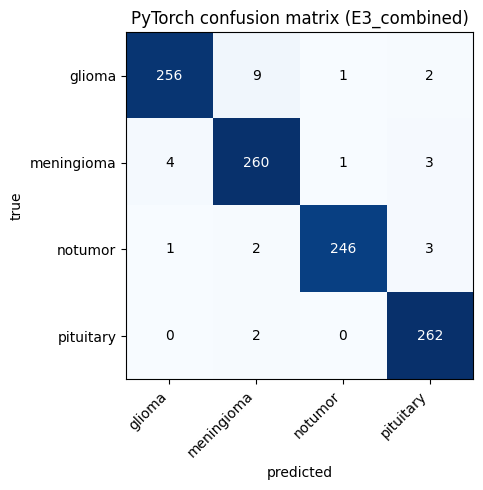

accuracy 0.9734  95% CI [0.9639, 0.9829]  -> differences smaller than this are noise


In [12]:
def load_model(name):
    cfg = {**BASE, **EXPS[name]}
    m = Net(cfg["arch"], cfg["head"], cfg["hidden"], cfg["dropout"], pretrained=False).to(DEVICE).to(memory_format=torch.channels_last)
    m.load_state_dict(torch.load(f"{OUT_DIR}/{name}/best.pt", map_location=DEVICE))
    set_trainable(m, []); m.eval()
    return m

TEST = {}
for tag, name in {"matched": "E0_matched_tf", "best": BEST}.items():
    lg = get_logits(load_model(name), X_test)
    TEST[tag] = dict(name=name, logits=lg, metrics=compute_metrics(lg, y_test, "test_loss"))
    print(tag, name, {k: round(v, 4) for k, v in TEST[tag]["metrics"].items()})

FINAL = TEST["best"]
prob = FINAL["logits"].softmax(1).numpy(); pred = prob.argmax(1); yt = y_test.numpy()
np.save(f"{OUT_DIR}/pt_test_probs.npy", prob)          # for the paired significance test
report = classification_report(yt, pred, target_names=CLASS_NAMES, digits=4, zero_division=0)
print(report); open(f"{OUT_DIR}/classification_report_pytorch.txt", "w").write(report)

cm = confusion_matrix(yt, pred, labels=range(4))
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(f"{OUT_DIR}/confusion_matrix_pytorch.csv")
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_yticks(range(4)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right"); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"PyTorch confusion matrix ({FINAL['name']})")
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix_pytorch.png", dpi=130); plt.show()

# how much can we trust a difference? (95 % bootstrap CI of accuracy on the test set)
rng = np.random.default_rng(SEED)
boots = [(pred[i] == yt[i]).mean() for i in (rng.integers(0, len(yt), len(yt)) for _ in range(2000))]
print(f"accuracy {np.mean(pred == yt):.4f}  95% CI [{np.percentile(boots, 2.5):.4f}, {np.percentile(boots, 97.5):.4f}]  -> differences smaller than this are noise")

28 errors of 1052
most common confusions (true -> predicted): [(('glioma', 'meningioma'), 9), (('meningioma', 'glioma'), 4), (('meningioma', 'pituitary'), 3), (('notumor', 'pituitary'), 3), (('glioma', 'pituitary'), 2)]
mean confidence | correct 0.929 | wrong 0.702


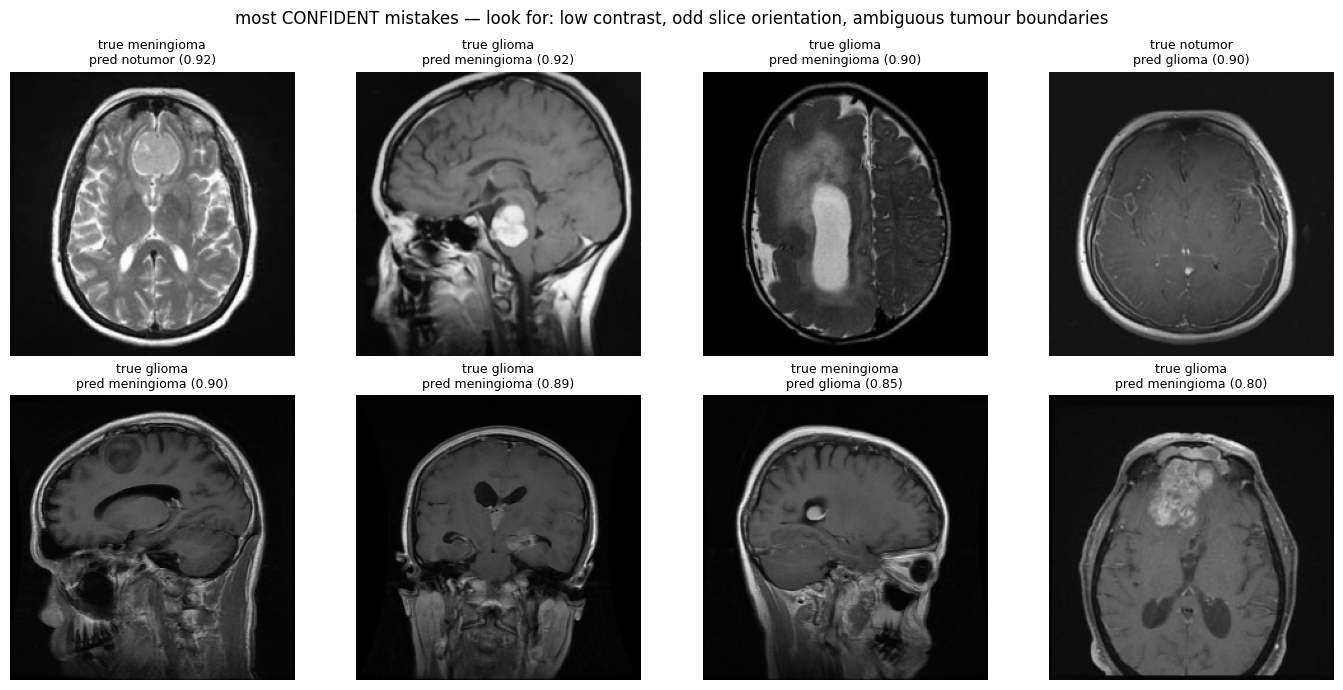

In [13]:
# error analysis: WHICH mistakes, how confident, what do they look like?
wrong = np.where(pred != yt)[0]; conf = prob.max(1)
print(f"{len(wrong)} errors of {len(yt)}")
print("most common confusions (true -> predicted):", Counter((CLASS_NAMES[yt[i]], CLASS_NAMES[pred[i]]) for i in wrong).most_common(5))
print(f"mean confidence | correct {conf[pred == yt].mean():.3f} | wrong {conf[wrong].mean() if len(wrong) else float('nan'):.3f}")
top = wrong[np.argsort(-conf[wrong])][:8]
if len(top):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, i in zip(axes.ravel(), top):
        ax.imshow(X_test[i].permute(1, 2, 0)); ax.set_title(f"true {CLASS_NAMES[yt[i]]}\npred {CLASS_NAMES[pred[i]]} ({conf[i]:.2f})", fontsize=9); ax.axis("off")
    plt.suptitle("most CONFIDENT mistakes — look for: low contrast, odd slice orientation, ambiguous tumour boundaries")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/top_errors.png", dpi=120); plt.show()

## 7. Grad-CAM (same method and same test images as Member 1)
Gradient of the predicted class **logit** w.r.t. the last conv block (`layer4` = Keras `conv5_block3_out`), channel-weighted, ReLU, normalized — identical recipe to the TF notebook.

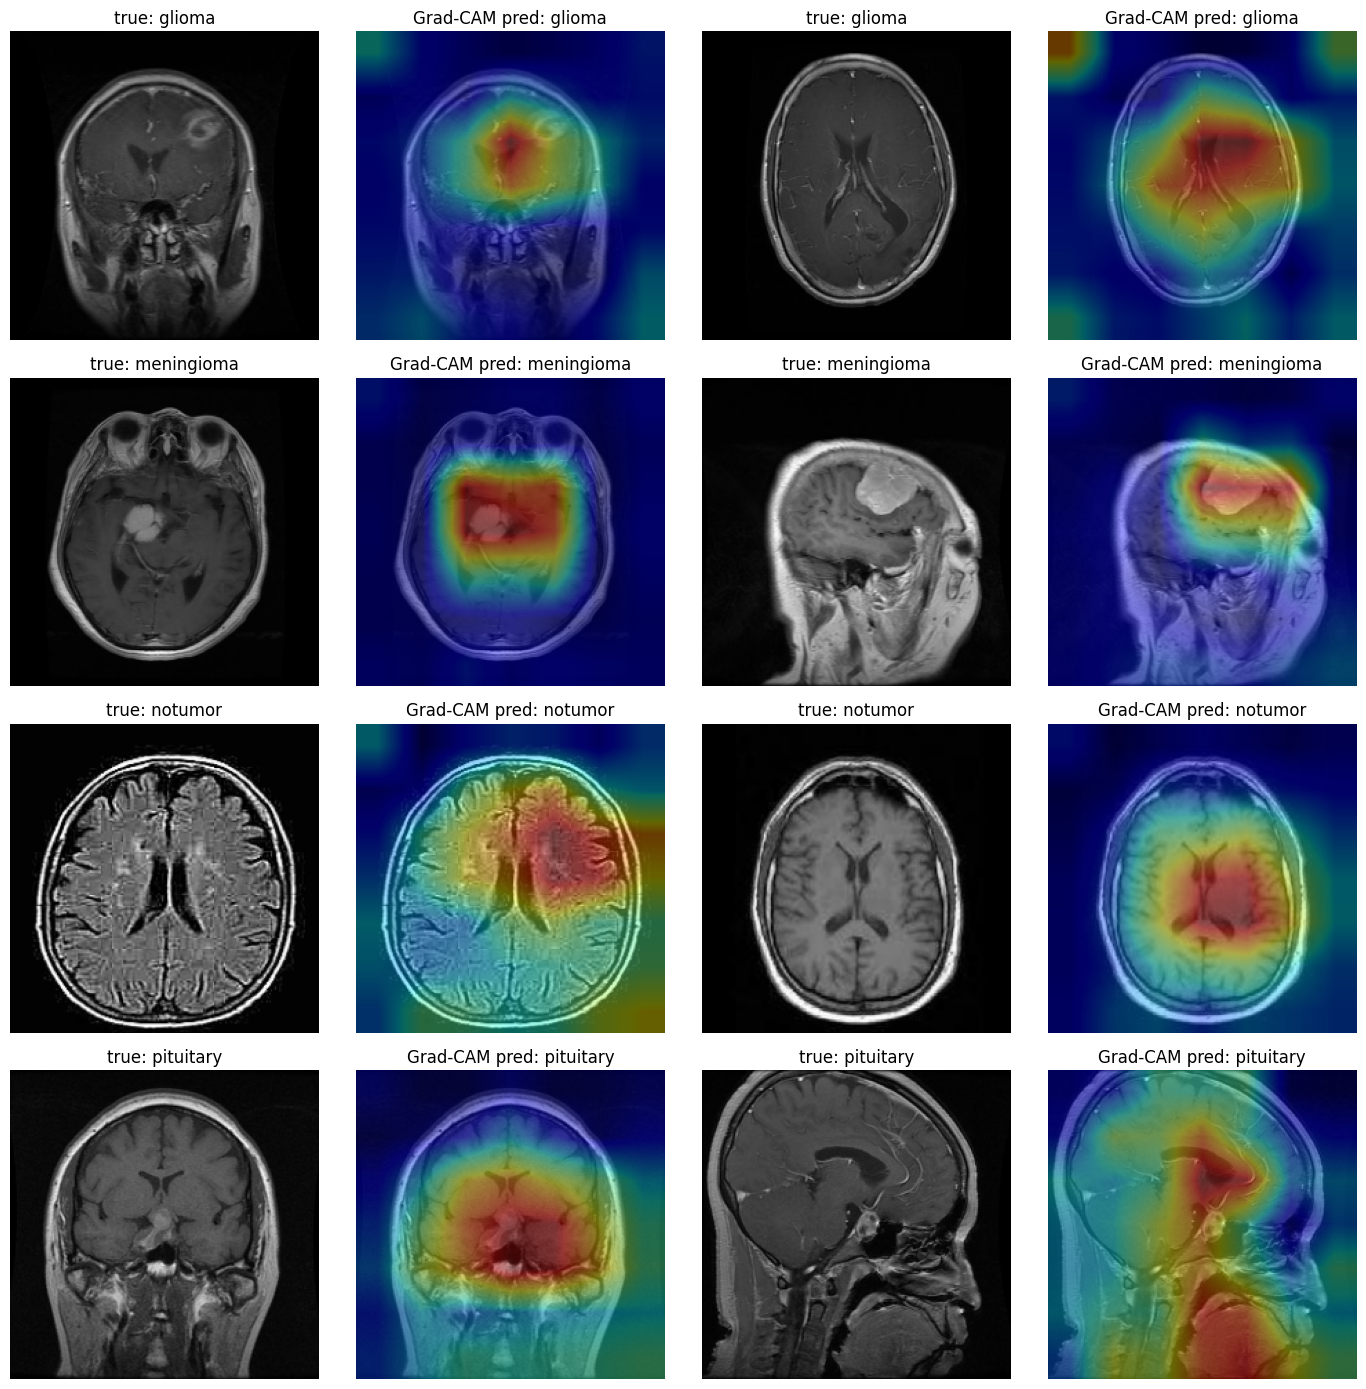

In [14]:
def gradcam(model, x_uint8):
    model.eval(); model.backbone_frozen = False
    store = {}
    def save_act(module, inp, out):
        store["a"] = out; out.retain_grad()            # must return None (a return value would replace the layer output)
    h = model.backbone.layer4.register_forward_hook(save_act)
    x = prep(x_uint8[None]).requires_grad_(True)       # input requires grad so a graph exists even if all weights are frozen
    logits = model(x); idx = int(logits.argmax(1)); logits[0, idx].backward(); h.remove()
    a = store["a"]; w = a.grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True)); cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
    model.backbone_frozen = True
    return cam, idx

gc_model = load_model(FINAL["name"])
samples = pd.concat([test_df[test_df["label_idx"] == i].sample(2, random_state=SEED) for i in range(4)])  # same picks as Member 1
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for k, (idx_row, row) in enumerate(samples.iterrows()):
    r, c = k // 2, (k % 2) * 2
    img = X_test[idx_row]; cam, p = gradcam(gc_model, img)
    axes[r, c].imshow(img.permute(1, 2, 0)); axes[r, c].set_title(f"true: {row['label']}")
    axes[r, c + 1].imshow(img.permute(1, 2, 0)); axes[r, c + 1].imshow(cam, cmap="jet", alpha=0.4)
    axes[r, c + 1].set_title(f"Grad-CAM pred: {CLASS_NAMES[p]}")
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gradcam_pytorch.png", dpi=130); plt.show()
# Check: is the heat on the tumour / sella region, or on the skull border / background? Border-only heat = shortcut learning.

## 8. TensorFlow vs PyTorch (reads Member 1's saved results)
Member 1: please add one line after the test evaluation so we can run a paired test: `np.save("outputs_tensorflow_aug/tf_test_probs.npy", y_prob)`.

,test_acc,precision,recall,f1,test_loss,trainable_params,total_params,model_MB,cpu_latency_ms,train_min,epochs
PyTorch (matched: E0_matched_tf),0.9458,0.9465,0.9462,0.9463,0.1527,14950404.0,23516228.0,94.3693,113.4535,4.4209,22.0
PyTorch (best: E3_combined),0.9734,0.9739,0.9735,0.9736,0.1287,15500164.0,24065988.0,96.5694,113.3624,5.2257,25.0
TensorFlow (Member 1),0.9639,0.9642,0.9642,0.9641,0.1598,14436868.0,23595908.0,210.5482,470.8274,26.8774,25.0


GPU used here: Tesla T4 (write down the GPU Member 1 used — speed numbers are only comparable on the same GPU)


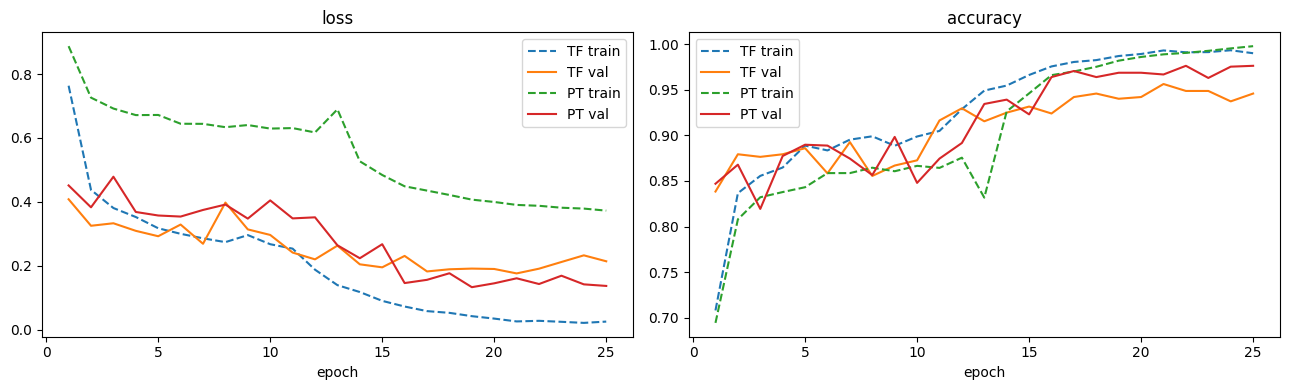

In [15]:
def latency_cpu(model, n=50):
    m = copy.deepcopy(model).cpu().eval(); m.backbone_frozen = True
    x = ((X_test[:1].float() / 255) - MEAN.cpu()) / STD.cpu()
    with torch.no_grad():
        for _ in range(5): m(x)
        t = time.time()
        for _ in range(n): m(x)
    return (time.time() - t) / n * 1000

def ckpt_size_mb(name): return os.path.getsize(f"{OUT_DIR}/{name}/best.pt") / 1e6

tf_json = f"{TF_DIR}/tensorflow_results.json"
tf = json.load(open(tf_json)) if os.path.exists(tf_json) else None
rows = {}
for tag in ("matched", "best"):
    name = TEST[tag]["name"]; r = results[name]; mt = TEST[tag]["metrics"]
    rows[f"PyTorch ({tag}: {name})"] = {"test_acc": mt["accuracy"], "precision": mt["precision_macro"], "recall": mt["recall_macro"],
        "f1": mt["f1_macro"], "test_loss": mt["test_loss"], "trainable_params": r["trainable_params_phase2"], "total_params": r["total_params"],
        "model_MB": ckpt_size_mb(name), "cpu_latency_ms": latency_cpu(load_model(name)), "train_min": r["total_training_time_sec"] / 60,
        "epochs": r["epochs_phase1"] + r["epochs_phase2"]}
if tf:
    m = tf["fine_tuned_test_metrics"]; c = tf["config"]
    rows["TensorFlow (Member 1)"] = {"test_acc": m["accuracy"], "precision": m["precision_macro"], "recall": m["recall_macro"], "f1": m["f1_macro"],
        "test_loss": m["test_loss"], "trainable_params": tf["trainable_params"], "total_params": tf["total_params"], "model_MB": tf["model_size_mb"],
        "cpu_latency_ms": tf["cpu_inference_latency_ms_single_image"], "train_min": c["total_training_time_sec"] / 60,
        "epochs": c["phase1_frozen_backbone"]["epochs_run"] + c["phase2_fine_tuning"]["epochs_run"]}
comparison = pd.DataFrame(rows).T
comparison.to_csv(f"{OUT_DIR}/framework_comparison.csv"); display(comparison.round(4))
print("GPU used here:", torch.cuda.get_device_name(0) if USE_AMP else "cpu", "(write down the GPU Member 1 used — speed numbers are only comparable on the same GPU)")

# side-by-side loss curves
tf_hist = f"{TF_DIR}/training_history.csv"
if os.path.exists(tf_hist):
    th = pd.read_csv(tf_hist); ph = pd.read_csv(f"{OUT_DIR}/{FINAL['name']}/training_history.csv")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, key, t in zip(axes, ("loss", "accuracy"), ("loss", "accuracy")):
        ax.plot(th["epoch"], th[key], "--", label="TF train"); ax.plot(th["epoch"], th["val_" + key], label="TF val")
        ax.plot(ph["epoch"], ph[key], "--", label="PT train"); ax.plot(ph["epoch"], ph["val_" + key], label="PT val")
        ax.set_title(t); ax.set_xlabel("epoch"); ax.legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/tf_vs_pt_curves.png", dpi=130); plt.show()

# paired significance (McNemar, exact) — needs Member 1's probabilities on the SAME test order
tf_probs = f"{TF_DIR}/tf_test_probs.npy"
if os.path.exists(tf_probs):
    from scipy.stats import binomtest
    tp = np.load(tf_probs).argmax(1)
    b = int(((tp == yt) & (pred != yt)).sum()); c_ = int(((tp != yt) & (pred == yt)).sum())
    print(f"TF right & PT wrong: {b} | TF wrong & PT right: {c_} | McNemar p = {binomtest(b, b + c_, 0.5).pvalue:.3f}  (p>0.05 -> no significant difference)")

## 9. Export for the FastAPI service (TorchScript, softmax included)
The service must apply the same preprocessing: RGB → bilinear resize to 224×224 **without antialiasing** → /255 → ImageNet mean/std (saved in `preprocessing_spec.json`).

In [16]:
class Export(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, x): return torch.softmax(self.m(x), dim=1)

cpu_model = copy.deepcopy(load_model(FINAL["name"])).cpu().eval(); cpu_model.backbone_frozen = False
ex = Export(cpu_model).eval()
xs = ((X_test[:8].float() / 255) - MEAN.cpu()) / STD.cpu()
ts = torch.jit.trace(ex, xs[:1]); MODEL_PATH = f"{MODEL_DIR}/model_{TEAM_ID}.pt"
ts.save(MODEL_PATH)
with torch.no_grad():
    assert torch.allclose(torch.jit.load(MODEL_PATH)(xs), ex(xs), atol=1e-5), "exported model differs"
print(MODEL_PATH, f"{os.path.getsize(MODEL_PATH) / 1e6:.1f} MB")

spec = {"framework": "pytorch", "image_size": IMAGE_SIZE, "color_mode": "RGB", "resize": "bilinear, antialias=False",
        "scale": "divide by 255", "mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225], "class_names": CLASS_NAMES,
        "augmentation": AUG, "split_source": SPLIT_SOURCE, "model": FINAL["name"], "config": results[FINAL["name"]]["config"]}
json.dump(spec, open(f"{OUT_DIR}/preprocessing_spec.json", "w"), indent=2)
json.dump({"experiments": results, "test_metrics": {k: v["metrics"] for k, v in TEST.items()}}, open(f"{OUT_DIR}/pytorch_results.json", "w"), indent=2)
print(sorted(os.listdir(OUT_DIR)))

model/model_34.pt 96.9 MB
['E0_matched_tf', 'E1_mlp_head', 'E2_higher_ft_lr', 'E3_combined', 'classification_report_pytorch.txt', 'confusion_matrix_pytorch.csv', 'confusion_matrix_pytorch.png', 'experiment_summary_val.csv', 'experiments_val_curves.png', 'framework_comparison.csv', 'gradcam_pytorch.png', 'preprocessing_spec.json', 'pt_test_probs.npy', 'pytorch_results.json', 'sample_augmentations.png', 'split_counts.csv', 'tf_vs_pt_curves.png', 'top_errors.png']


In [17]:
try:
    from google.colab import files
    shutil.make_archive("outputs_pytorch", "zip", OUT_DIR)
    files.download("outputs_pytorch.zip")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

copying from content to mydrive the model weights

In [18]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [22]:

source_folder = "/content/model/model_34.pt"
destination_folder = "/content/drive/MyDrive/FCDS/AI Platforms/assignment1 pytorch best weights"


!cp -r {source_folder} {destination_folder}


cp: target 'weights': No such file or directory


cp: cannot create regular file '/content/drive/MyDrive/FCDS/AI Platforms/assignment1 pytorch best weights/': Not a directory
